<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/20_fuego/22_fuego_patron_puntos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 22 · Patrón espacial de los focos de calor en la Altillanura

**Autora:** Michelle

**Pregunta:** ¿los focos de calor se agrupan en el espacio o están repartidos al azar? ¿A qué escala se agrupan, dónde se concentran y cómo cambió eso entre 2003–2013 y 2014–2025?

**Entradas** (`datos/comunes/`):
- `firms_altillanura_puntos.gpkg` (cuaderno 03, DVC): detecciones MODIS Terra + Aqua.
- `altillanura_municipios.gpkg` (cuaderno 01, DVC).
- `grilla_2km.gpkg` (cuaderno 02, Daniel, DVC): solo para la parte B.

**Salidas:**
- Parte A: `modulos/clima_fuego/resultados/22_cuadrantes.csv`, `22_ripley.csv` y figuras `22_*.png`.
- Parte B (cuando exista la grilla): `datos/comunes/focos_celda.csv` (una fila por celda) y `datos/comunes/focos_celda_anual.csv` (celda × año).

**Métodos:** densidad de focos suavizada con núcleo gaussiano, prueba de cuadrantes (índice varianza/media) y función K de Ripley transformada a L(d) − d, con 99 simulaciones de aleatoriedad espacial completa (CSR) como banda de referencia.

**Nota:** cada foco es un píxel caliente de ~1 km detectado por MODIS, no un incendio. Se usan los datos desde enero de 2003 (Terra + Aqua).

## Paso 1. Preparar el entorno

In [1]:
# Rutas del proyecto: funcionan en Colab y en local (ver 00_configuracion)
import os, sys, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    # Los datos crudos pesados (MGN, CSV de FIRMS, copia del ONI) siguen en Drive
    CRUDOS = '/content/drive/MyDrive/proyecto-altillanura-STDG/datos/crudos'
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        !git clone -q {REPO} {RAIZ}
    # Mientras el PR #3 no esté unido a main, los datos comunes están en esta rama
    if not os.path.exists(f'{RAIZ}/datos/comunes/oni_mensual.csv'):
        !git -C {RAIZ} fetch -q origin feature/clima-fuego-datos
        !git -C {RAIZ} checkout -q feature/clima-fuego-datos
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/<etapa>/
    CRUDOS = os.path.join(RAIZ, 'datos', 'crudos')

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
GRAFICAS = os.path.join(RAIZ, 'modulos', 'clima_fuego', 'graficas')
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    """Baja de DVC un archivo pesado del repo (por ejemplo un .gpkg) si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

print('Raíz del repo:', RAIZ)
print('Crudos:', CRUDOS, '| existe:', os.path.exists(CRUDOS))

RESULTADOS = os.path.join(RAIZ, 'modulos', 'clima_fuego', 'resultados')
os.makedirs(RESULTADOS, exist_ok=True)

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
from scipy import stats
from scipy.ndimage import gaussian_filter
from scipy.spatial.distance import cdist
SEMILLA = 2026

Mounted at /content/drive
Raíz del repo: /content/Proyecto-ALTILLANURA
Crudos: /content/drive/MyDrive/proyecto-altillanura-STDG/datos/crudos | existe: True


## Paso 2. Cargar los focos y el área de estudio
Todo se lleva a EPSG:9377 (MAGNA-SIRGAS Origen Nacional, en metros) para medir distancias y áreas.
La **temporada seca** de un año *y* va de diciembre de *y−1* a marzo de *y*.

In [3]:
traer('datos/comunes/altillanura_municipios.gpkg')
traer('datos/comunes/firms_altillanura_puntos.gpkg')

mpios = gpd.read_file(f'{COMUNES}/altillanura_municipios.gpkg').to_crs(9377)
area_estudio = shapely.union_all(mpios.geometry.values)
AREA_KM2 = area_estudio.area / 1e6

pts = gpd.read_file(f'{COMUNES}/firms_altillanura_puntos.gpkg').to_crs(9377)
pts['fecha'] = pd.to_datetime(pts['acq_date'])
pts = pts[pts['fecha'] >= '2003-01-01'].copy()
pts['anio'] = pts['fecha'].dt.year
pts['mes'] = pts['fecha'].dt.month
pts['seca'] = pts['mes'].isin([12, 1, 2, 3])
pts['temporada'] = np.where(pts['mes'] == 12, pts['anio'] + 1, pts['anio'])
pts['x'] = pts.geometry.x
pts['y'] = pts.geometry.y

ANIOS = sorted(pts['anio'].unique())
print(f'Área de estudio: {AREA_KM2:,.0f} km²')
print(f'Focos 2003–2025: {len(pts):,} | en temporada seca: {pts["seca"].mean():.0%}')
print(f'Años: {ANIOS[0]}–{ANIOS[-1]} ({len(ANIOS)} años)')

Bajado de DVC: datos/comunes/altillanura_municipios.gpkg
Bajado de DVC: datos/comunes/firms_altillanura_puntos.gpkg
Área de estudio: 135,649 km²
Focos 2003–2025: 206,666 | en temporada seca: 77%
Años: 2003–2025 (23 años)


## Paso 3. Densidad de focos
Se cuentan los focos en una malla de 2 km y se suavizan con un núcleo gaussiano de 10 km (σ = 5 celdas).
El resultado es la **densidad media en focos por km² por año**. Se compara además 2003–2013 con 2014–2025.

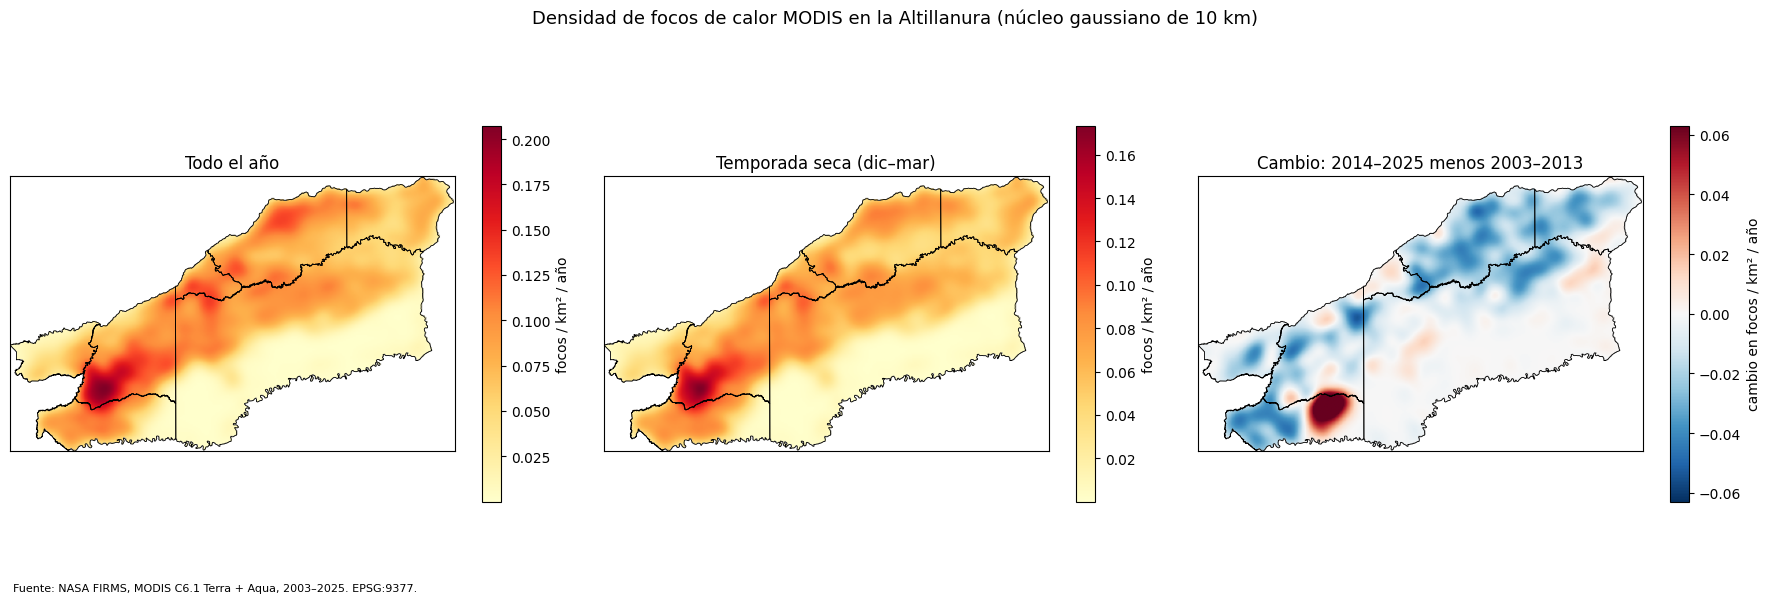

Densidad media por municipio (descriptiva):
                focos_por_anio  area_km2  focos_100km2_anio
mpio_cnmbr                                                 
PUERTO GAITÁN           2000.7   17200.8               11.6
SANTA ROSALÍA            398.7    3679.0               10.8
LA PRIMAVERA            1710.7   18492.1                9.3
MAPIRIPÁN                874.8   11917.5                7.3
PUERTO CARREÑO           847.0   12142.3                7.0
PUERTO LÓPEZ             337.0    6898.2                4.9
CUMARIBO                2816.6   65319.3                4.3


In [4]:
TAM = 2000          # tamaño de la celda de la malla, en metros
SIGMA = 5           # suavizado: 5 celdas = 10 km
xmin, ymin, xmax, ymax = area_estudio.bounds
bx = np.arange(xmin, xmax + TAM, TAM)
by = np.arange(ymin, ymax + TAM, TAM)
cx, cy = np.meshgrid((bx[:-1] + bx[1:]) / 2, (by[:-1] + by[1:]) / 2)
dentro = shapely.contains_xy(area_estudio, cx, cy)

def densidad(sub, n_anios):
    h, _, _ = np.histogram2d(sub['y'], sub['x'], bins=[by, bx])
    d = gaussian_filter(h, SIGMA) / (TAM / 1000) ** 2 / n_anios   # focos / km² / año
    return np.where(dentro, d, np.nan)

dens_total = densidad(pts, len(ANIOS))
dens_seca = densidad(pts[pts['seca']], len(ANIOS))
p1 = pts[pts['anio'].between(2003, 2013)]
p2 = pts[pts['anio'].between(2014, 2025)]
cambio = densidad(p2, 12) - densidad(p1, 11)

ext = [bx[0], bx[-1], by[0], by[-1]]
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, z, titulo, cmap in [(axes[0], dens_total, 'Todo el año', 'YlOrRd'),
                            (axes[1], dens_seca, 'Temporada seca (dic–mar)', 'YlOrRd')]:
    im = ax.imshow(z, origin='lower', extent=ext, cmap=cmap)
    plt.colorbar(im, ax=ax, shrink=0.7, label='focos / km² / año')
    ax.set_title(titulo)
lim = np.nanpercentile(np.abs(cambio), 99)
im = axes[2].imshow(cambio, origin='lower', extent=ext, cmap='RdBu_r', vmin=-lim, vmax=lim)
plt.colorbar(im, ax=axes[2], shrink=0.7, label='cambio en focos / km² / año')
axes[2].set_title('Cambio: 2014–2025 menos 2003–2013')
for ax in axes:
    mpios.boundary.plot(ax=ax, color='black', linewidth=0.6)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(''); ax.set_ylabel('')
fig.suptitle('Densidad de focos de calor MODIS en la Altillanura (núcleo gaussiano de 10 km)', fontsize=13)
fig.text(0.01, 0.01, 'Fuente: NASA FIRMS, MODIS C6.1 Terra + Aqua, 2003–2025. EPSG:9377.', fontsize=8)
plt.tight_layout()
plt.savefig(f'{GRAFICAS}/22_densidad_focos.png', dpi=150, bbox_inches='tight')
plt.show()

por_mpio = (pts.groupby('mpio_cnmbr').size() / len(ANIOS)).rename('focos_por_anio').to_frame()
por_mpio['area_km2'] = mpios.set_index('mpio_cnmbr').area / 1e6
por_mpio['focos_100km2_anio'] = por_mpio['focos_por_anio'] / por_mpio['area_km2'] * 100
print('Densidad media por municipio (descriptiva):')
print(por_mpio.sort_values('focos_100km2_anio', ascending=False).round(1).to_string())

## Paso 4. Prueba de cuadrantes
El área se divide en cuadrados de 20 km y se cuentan los focos de cada uno.
Si los focos estuvieran repartidos al azar (proceso de Poisson), la varianza de los conteos sería igual a la media: **índice varianza/media (IVM) ≈ 1**.
IVM > 1 indica agrupamiento. Se calcula con todos los años y año por año.

In [5]:
LADO = 20000
qx = np.arange(xmin, xmax + LADO, LADO)
qy = np.arange(ymin, ymax + LADO, LADO)
qcx, qcy = np.meshgrid((qx[:-1] + qx[1:]) / 2, (qy[:-1] + qy[1:]) / 2)
q_dentro = shapely.contains_xy(area_estudio, qcx, qcy)

def cuadrantes(sub):
    h, _, _ = np.histogram2d(sub['y'], sub['x'], bins=[qy, qx])
    c = h[q_dentro]
    ivm = c.var(ddof=1) / c.mean()
    chi2 = (len(c) - 1) * ivm
    p = stats.chi2.sf(chi2, len(c) - 1)
    return pd.Series({'cuadrantes': len(c), 'media': c.mean(), 'varianza': c.var(ddof=1),
                      'IVM': ivm, 'chi2': chi2, 'p': p})

filas = {'2003–2025 (todo)': cuadrantes(pts), 'Temporada seca (todo)': cuadrantes(pts[pts['seca']])}
filas.update({str(a): cuadrantes(pts[pts['anio'] == a]) for a in ANIOS})
cuad = pd.DataFrame(filas).T
print(cuad.loc[['2003–2025 (todo)', 'Temporada seca (todo)']].round(3).to_string())
print(f"\nIVM por año: mínimo {cuad.loc[[str(a) for a in ANIOS], 'IVM'].min():.1f}, "
      f"máximo {cuad.loc[[str(a) for a in ANIOS], 'IVM'].max():.1f}. "
      f"Años con p < 0,05: {(cuad.loc[[str(a) for a in ANIOS], 'p'] < 0.05).sum()} de {len(ANIOS)}")

                       cuadrantes    media    varianza      IVM        chi2    p
2003–2025 (todo)            335.0  601.149  185433.421  308.465  103027.263  0.0
Temporada seca (todo)       335.0  462.424  111344.940  240.785   80422.338  0.0

IVM por año: mínimo 13.5, máximo 26.3. Años con p < 0,05: 23 de 23


## Paso 5. Función K de Ripley y L(d) − d
Para cada distancia *d*, K(d) mide cuántos focos hay en promedio a menos de *d* de un foco, dividido por la densidad.
Se usa la transformación **L(d) − d**: vale 0 si los focos están al azar, es positiva si se agrupan a esa escala y negativa si se repelen.

- Para que el cálculo sea manejable, en cada año se toma una muestra al azar de 1.500 focos (sin repetir coordenadas).
- **Corrección de borde:** solo cuentan como centro los focos que están a más de *d* del límite del área.
- **Banda de referencia:** 99 simulaciones de focos al azar dentro del área (CSR). Si la curva sale de la banda, el agrupamiento es significativo (α ≈ 0,02).

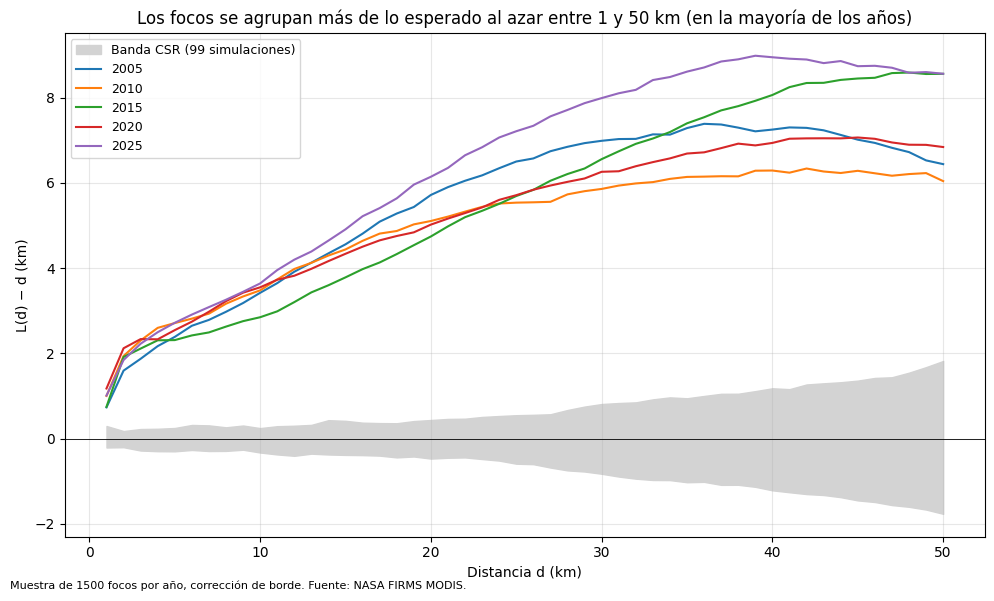

2005: agrupamiento significativo en 50 de 50 distancias; máximo de L(d) − d = 7.4 km en d = 36 km
2010: agrupamiento significativo en 50 de 50 distancias; máximo de L(d) − d = 6.3 km en d = 42 km
2015: agrupamiento significativo en 50 de 50 distancias; máximo de L(d) − d = 8.6 km en d = 48 km
2020: agrupamiento significativo en 50 de 50 distancias; máximo de L(d) − d = 7.1 km en d = 45 km
2025: agrupamiento significativo en 50 de 50 distancias; máximo de L(d) − d = 9.0 km en d = 39 km


In [6]:
N_MUESTRA = 1500
N_SIM = 99
D = np.arange(1000, 50001, 1000)          # distancias de 1 a 50 km
borde = area_estudio.boundary
rng = np.random.default_rng(SEMILLA)

def l_menos_d(x, y):
    xy = np.column_stack([x, y])
    n = len(xy)
    dist_borde = shapely.distance(shapely.points(xy), borde)
    orden = np.sort(cdist(xy, xy), axis=1)[:, 1:]           # sin la distancia a sí mismo
    vecinos = np.stack([np.searchsorted(fila, D, side='right') for fila in orden])
    lam = n / area_estudio.area
    K = np.array([vecinos[dist_borde >= d, k].mean() / lam if (dist_borde >= d).sum() > 30 else np.nan
                  for k, d in enumerate(D)])
    return np.sqrt(K / np.pi) - D

def csr(n):
    x0, y0, x1, y1 = area_estudio.bounds
    xs, ys = [], []
    while sum(len(v) for v in xs) < n:
        px = rng.uniform(x0, x1, 3 * n); py = rng.uniform(y0, y1, 3 * n)
        ok = shapely.contains_xy(area_estudio, px, py)
        xs.append(px[ok]); ys.append(py[ok])
    return np.concatenate(xs)[:n], np.concatenate(ys)[:n]

sims = np.array([l_menos_d(*csr(N_MUESTRA)) for _ in range(N_SIM)])
banda_inf, banda_sup = np.nanmin(sims, axis=0), np.nanmax(sims, axis=0)

ANIOS_RIPLEY = [2005, 2010, 2015, 2020, 2025]
curvas = {}
for a in ANIOS_RIPLEY:
    sub = pts[pts['anio'] == a].drop_duplicates(['x', 'y'])
    sub = sub.sample(min(N_MUESTRA, len(sub)), random_state=SEMILLA)
    curvas[a] = l_menos_d(sub['x'].values, sub['y'].values)

ripley = pd.DataFrame(curvas, index=D / 1000)
ripley.index.name = 'distancia_km'
ripley['banda_inf'] = banda_inf
ripley['banda_sup'] = banda_sup

fig, ax = plt.subplots(figsize=(10, 6))
ax.fill_between(D / 1000, banda_inf / 1000, banda_sup / 1000, color='lightgray',
                label=f'Banda CSR ({N_SIM} simulaciones)')
for a in ANIOS_RIPLEY:
    ax.plot(D / 1000, np.array(curvas[a]) / 1000, label=str(a))
ax.axhline(0, color='black', linewidth=0.6)
ax.set_xlabel('Distancia d (km)')
ax.set_ylabel('L(d) − d (km)')
signif = np.mean([np.array(curvas[a]) > banda_sup for a in ANIOS_RIPLEY], axis=0) > 0.5
if signif.any():
    titulo = (f'Los focos se agrupan más de lo esperado al azar entre {D[signif].min() / 1000:.0f} '
              f'y {D[signif].max() / 1000:.0f} km (en la mayoría de los años)')
else:
    titulo = 'No se detecta agrupamiento de los focos por encima de lo esperado al azar'
ax.set_title(titulo)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
fig.text(0.01, 0.01, f'Muestra de {N_MUESTRA} focos por año, corrección de borde. Fuente: NASA FIRMS MODIS.', fontsize=8)
plt.tight_layout()
plt.savefig(f'{GRAFICAS}/22_ripley_l.png', dpi=150, bbox_inches='tight')
plt.show()

for a in ANIOS_RIPLEY:
    c = np.array(curvas[a])
    fuera = c > banda_sup
    k = int(np.nanargmax(c))
    print(f'{a}: agrupamiento significativo en {fuera.sum()} de {len(D)} distancias; '
          f'máximo de L(d) − d = {c[k] / 1000:.1f} km en d = {D[k] / 1000:.0f} km')

**Cómo leerlo:** la distancia donde L(d) − d alcanza su máximo es la escala típica de los agrupamientos de focos. El título de la figura se escribe solo según el rango de distancias donde la mayoría de los años sale de la banda.

## Paso 6. Parte B: focos por celda de 2 km
Se activa cuando la grilla de Daniel (`datos/comunes/grilla_2km.gpkg`, con la columna `id_celda`) está en el repo.
Si todavía no está, la celda avisa y no hace nada.

In [7]:
RUTA_GRILLA = 'datos/comunes/grilla_2km.gpkg'
try:
    traer(RUTA_GRILLA)
except Exception as e:
    print('La grilla todavía no está en DVC:', e)

if os.path.exists(os.path.join(RAIZ, RUTA_GRILLA)):
    grilla = gpd.read_file(os.path.join(RAIZ, RUTA_GRILLA)).to_crs(9377)
    assert 'id_celda' in grilla.columns, f'La grilla no tiene id_celda. Columnas: {list(grilla.columns)}'
    grilla['area_km2'] = grilla.area / 1e6

    unidos = gpd.sjoin(pts[['anio', 'temporada', 'seca', 'geometry']],
                       grilla[['id_celda', 'geometry']], predicate='within', how='inner')
    print(f'Focos asignados a una celda: {len(unidos):,} de {len(pts):,}')

    idx = pd.MultiIndex.from_product([grilla['id_celda'], ANIOS], names=['id_celda', 'anio'])
    anual = (unidos.groupby(['id_celda', 'anio']).size().rename('focos')
             .reindex(idx, fill_value=0).reset_index())

    temporadas = list(range(2004, 2026))
    idx_t = pd.MultiIndex.from_product([grilla['id_celda'], temporadas], names=['id_celda', 'temporada'])
    seca = (unidos[unidos['seca'] & unidos['temporada'].isin(temporadas)]
            .groupby(['id_celda', 'temporada']).size().rename('focos')
            .reindex(idx_t, fill_value=0).reset_index())

    resumen = pd.DataFrame({
        'focos_total_2003_2025': anual.groupby('id_celda')['focos'].sum(),
        'focos_media_anual': anual.groupby('id_celda')['focos'].mean(),
        'focos_temporada_seca_media': seca.groupby('id_celda')['focos'].mean(),
        'anios_con_focos': anual.assign(f=anual['focos'] > 0).groupby('id_celda')['f'].sum(),
    })
    resumen['focos_km2_anio'] = resumen['focos_media_anual'] / grilla.set_index('id_celda')['area_km2']
    resumen = resumen.reset_index()

    resumen.round(4).to_csv(f'{COMUNES}/focos_celda.csv', index=False)
    anual.to_csv(f'{COMUNES}/focos_celda_anual.csv', index=False)
    print('Guardado: focos_celda.csv y focos_celda_anual.csv')
    print(resumen.describe().round(2).to_string())

    fig, ax = plt.subplots(figsize=(10, 7))
    grilla.merge(resumen, on='id_celda').plot(column='focos_km2_anio', cmap='YlOrRd', scheme='quantiles',
                                              k=6, legend=True, ax=ax, linewidth=0)
    mpios.boundary.plot(ax=ax, color='black', linewidth=0.6)
    ax.set_title('Focos de calor por km² y por año en cada celda de 2 km (2003–2025)')
    ax.set_axis_off()
    plt.savefig(f'{GRAFICAS}/22_focos_por_celda.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Parte B pendiente: falta datos/comunes/grilla_2km.gpkg (cuaderno 02 de Daniel).')

La grilla todavía no está en DVC: Command '['/usr/bin/python3', '-m', 'dvc', 'pull', '-q', 'datos/comunes/grilla_2km.gpkg']' returned non-zero exit status 1.
Parte B pendiente: falta datos/comunes/grilla_2km.gpkg (cuaderno 02 de Daniel).


## Paso 7. Guardar resultados

In [8]:
cuad.round(4).to_csv(f'{RESULTADOS}/22_cuadrantes.csv')
(ripley / 1000).round(3).rename(columns=str).to_csv(f'{RESULTADOS}/22_ripley.csv')
print('Resultados:', sorted(f for f in os.listdir(RESULTADOS) if f.startswith('22_')))
print('Gráficas:', sorted(f for f in os.listdir(GRAFICAS) if f.startswith('22_')))

if EN_COLAB:   # descarga resultados, gráficas y (si existen) los CSV por celda
    import shutil, glob
    from google.colab import files
    destino = '/content/resultados_22'
    os.makedirs(destino, exist_ok=True)
    for f in (glob.glob(f'{RESULTADOS}/22_*') + glob.glob(f'{GRAFICAS}/22_*')
              + glob.glob(f'{COMUNES}/focos_celda*.csv')):
        shutil.copy(f, destino)
    shutil.make_archive(destino, 'zip', destino)
    files.download(destino + '.zip')

Resultados: ['22_cuadrantes.csv', '22_ripley.csv']
Gráficas: ['22_densidad_focos.png', '22_ripley_l.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>